In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", 50)

1) Importación y exploración inicial

In [3]:
RUTA = "datasetsWC26/"

matches_raw   = pd.read_csv(RUTA + "matches_mundial2026.csv",     sep=";", encoding="utf-8-sig")
register_raw  = pd.read_csv(RUTA + "2026match_register.csv",      sep=";", encoding="utf-8-sig")
squads_raw    = pd.read_csv(RUTA + "2026squads_and_players.csv",  sep=";", encoding="utf-8-sig")
stats_raw     = pd.read_csv(RUTA + "2026player_stats.csv",        sep=";", encoding="utf-8-sig")
lineups_raw   = pd.read_csv(RUTA + "2026match_lineups.csv",       sep=";", encoding="utf-8-sig")
teams_raw     = pd.read_csv(RUTA + "2026nationalteams.csv",       sep=",", encoding="utf-8-sig")
venues_raw    = pd.read_csv(RUTA + "worldcup_venues.csv",         sep=";", encoding="utf-8-sig")
referees_raw  = pd.read_csv(RUTA + "index_referees.csv",          sep=";", encoding="utf-8-sig")
stages_raw    = pd.read_csv(RUTA + "tournament_stages.csv",       sep=",", encoding="utf-8-sig")
mundiales_raw = pd.read_csv(RUTA + "matches_mundial202.csv",      sep=",", encoding="utf-8-sig")
eurofem_raw   = pd.read_csv(RUTA + "2001eurocopa_fem_stats.csv",  sep=",", encoding="utf-8-sig")

Resumen de cada DataFrame

In [4]:
def resumen(df):
    return pd.DataFrame({
        "dtype":df.dtypes,
        "nulos":df.isna().sum(),
        "pct_nulos":df.isna().mean().mul(100).round(1),
        "n_unicos":df.nunique(dropna=False)
    })

In [5]:
tablas={"matches":matches_raw, "register": register_raw, "squads":squads_raw,
        "stats":stats_raw, "lineups":lineups_raw, "teams":teams_raw, "venues":venues_raw,
        "referees":referees_raw, "stages":stages_raw, "mundiales_202x":mundiales_raw,
          "eurocopa_fem":eurofem_raw}

for nombre,df in tablas.items():
    print("=" * 50)
    print(nombre, "->", df.shape)
    display(df.head(3))
    df.info() #tipos y no nulos por columna
    print("Nulos:", df.isna().sum()) #nulos por columna
    print("Duplicados:", df.duplicated().sum())   #filas repetidas

matches -> (110, 19)


,match_id,date,kickoff_time_utc,stage_id,venue_id,home_team_id,away_team_id,home_score,away_score,home_penalty_score,away_penalty_score,status,result_type,home_xg,away_xg,referee_id,player_of_the_match_id,capacidad_estadio_pct,clima
0,1,11/06/2026,19:00:00,1,1,1,2,2,0,NaN,NaN,Completed,Regular,184,52,42.0,16,63.1,soleado
1,2,11/06/2026,23:00:00,1,7,3,4,2,1,NaN,NaN,Completed,Regular,145,112,5.0,58,91.2,soleado
2,3,06/12/2026,19:00:00,1,6,5,6,1,1,NaN,NaN,Completed,Regular,135,98,15.0,112,NaN,NaN


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110 entries, 0 to 109
Data columns (total 19 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   match_id                110 non-null    int64  
 1   date                    110 non-null    object 
 2   kickoff_time_utc        110 non-null    object 
 3   stage_id                110 non-null    int64  
 4   venue_id                110 non-null    int64  
 5   home_team_id            110 non-null    int64  
 6   away_team_id            110 non-null    int64  
 7   home_score              110 non-null    int64  
 8   away_score              110 non-null    int64  
 9   home_penalty_score      4 non-null      float64
 10  away_penalty_score      4 non-null      float64
 11  status                  110 non-null    object 
 12  result_type             110 non-null    object 
 13  home_xg                 110 non-null    int64  
 14  away_xg                 110 non-null    in

,event_id,match_id,minute,event_type,team_id,player_id
0,1,1.0,9.0,Goal,1.0,16.0
1,2,1.0,9.0,Assist,1.0,6.0
2,3,1.0,17.0,Yellow Card,2.0,30.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 864 entries, 0 to 863
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   event_id    864 non-null    int64  
 1   match_id    849 non-null    float64
 2   minute      811 non-null    float64
 3   event_type  849 non-null    object 
 4   team_id     849 non-null    float64
 5   player_id   849 non-null    float64
dtypes: float64(4), int64(1), object(1)
memory usage: 40.6+ KB
Nulos: event_id       0
match_id      15
minute        53
event_type    15
team_id       15
player_id     15
dtype: int64
Duplicados: 20
squads -> (1248, 8)


,player_id,team_id,player_name,position,club_team,market_value_eur,caps,international_goals
0,1,1,José Raúl Rangel,GK,CD Guadalajara,8.9336,15,0
1,2,1,Jorge Eduardo Sanchez,DEF,PAOK Saloniki,24.6286,59,3
2,3,1,César Jasib Montes,DEF,FC Lokomotiv Moscow,10.9126,69,4


... (13 outputs left out)

,home_team,away_team,home_score,home_xg,home_penalty,away_score,away_xg,away_penalty,home_manager,home_captain,away_manager,away_captain,Attendance,Venue,Officials,Round,Date,Score,Referee,Notes,Host,Year,home_goal,away_goal,home_goal_long,away_goal_long,home_own_goal,away_own_goal,home_penalty_goal,away_penalty_goal,home_penalty_miss_long,away_penalty_miss_long,home_penalty_shootout_goal_long,away_penalty_shootout_goal_long,home_penalty_shootout_miss_long,away_penalty_shootout_miss_long,home_red_card,away_red_card,home_yellow_red_card,away_yellow_red_card,home_yellow_card_long,away_yellow_card_long,home_substitute_in_long,away_substitute_in_long,asistencia_estadio,temperatura_c
0,Argentina,France,3,3.3,4.0,3,2.2,2.0,Lionel Scaloni,Lionel Messi,Didier Deschamps,Hugo Lloris,88966,"Lusail Iconic Stadium, Lusail",Szymon Marciniak (Referee) · Paweł Sokolnicki ...,Final,2022-12-18,(4) 3–3 (2),Szymon Marciniak,Argentina won on penalty kicks following extra...,Qatar,2022,Ángel Di María · 36|Lionel Messi · 108,Kylian Mbappé · 81,['36&rsquor;|2:0|Ángel Di María|Assist:|Alexis...,['81&rsquor;|2:2|Kylian Mbappé|Assist:|Marcus ...,NaN,NaN,Lionel Messi (P) · 23,Kylian Mbappé (P) · 80|Kylian Mbappé (P) · 118,NaN,NaN,"['2|1:1|Lionel Messi', '4|2:1|Paulo Dybala', '...","['1|0:1|Kylian Mbappé', '7|3:2|Randal Kolo Mua...",NaN,"['3|1:1|Kingsley Coman', '5|2:1|Aurélien Tchou...",NaN,NaN,NaN,NaN,"['45+7&rsquor;|2:0|Enzo Fernández', '90+8&rsqu...","['55&rsquor;|2:0|Adrien Rabiot', '87&rsquor;|2...",['64&rsquor;|2:0|Marcos Acuña|for Ángel Di Mar...,['41&rsquor;|2:0|Randal Kolo Muani|for Ousmane...,88966.0,31.5
1,Croatia,Morocco,2,0.7,NaN,1,1.2,NaN,Zlatko Dalić,Luka Modrić,Hoalid Regragui,Hakim Ziyech,44137,"Khalifa International Stadium, Doha",Abdulrahman Ibrahim Al Jassim (Referee) · Tale...,Third-place match,2022-12-17,2–1,Abdulrahman Ibrahim Al Jassim,NaN,Qatar,2022,Joško Gvardiol · 7|Mislav Oršić · 42,Achraf Dari · 9,['7&rsquor;|1:0|Joško Gvardiol|Assist:|Ivan Pe...,['9&rsquor;|1:1|Achraf Dari'],NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"['69&rsquor;|2:1|Azzedine Ounahi', '84&rsquor;...",['61&rsquor;|2:1|Nikola Vlašić|for Andrej Kram...,['46&rsquor;|2:1|Ilias Chair|for Abdelhamid Sa...,44137.0,23.2
2,France,Morocco,2,2.0,NaN,0,0.9,NaN,Didier Deschamps,Hugo Lloris,Hoalid Regragui,Romain Saïss,68294,"Al Bayt Stadium, Al Khor",César Arturo Ramos (Referee) · Alberto Morín (...,Semi-finals,2022-12-14,2–0,César Arturo Ramos,NaN,Qatar,2022,Theo Hernández · 5|Randal Kolo Muani · 79,NaN,"['5&rsquor;|1:0|Theo Hernández', '79&rsquor;|2...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,['27&rsquor;|1:0|Sofiane Boufal'],['65&rsquor;|1:0|Marcus Thuram|for Olivier Gir...,['21&rsquor;|1:0|Selim Amallah|for Romain Saïs...,68294.0,28.5


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 979 entries, 0 to 978
Data columns (total 46 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   home_team                        979 non-null    object 
 1   away_team                        979 non-null    object 
 2   home_score                       979 non-null    int64  
 3   home_xg                          131 non-null    float64
 4   home_penalty                     35 non-null     float64
 5   away_score                       979 non-null    int64  
 6   away_xg                          131 non-null    float64
 7   away_penalty                     35 non-null     float64
 8   home_manager                     979 non-null    object 
 9   home_captain                     654 non-null    object 
 10  away_manager                     979 non-null    object 
 11  away_captain                     654 non-null    object 
 12  Attendance            

,id_match,home_team,away_team,home_team_code,away_team_code,home_score,away_score,home_penalty,away_penalty,home_score_total,away_score_total,winner,winner_reason,year,date,date_time,utc_offset_hours,group_name,matchday_name,condition_humidity,condition_pitch,condition_temperature,condition_weather,condition_wind_speed,status,type,round,round_mode,match_attendance,stadium_id,stadium_country_code,stadium_capacity,stadium_latitude,stadium_longitude,stadium_pitch_length,stadium_pitch_width,goals,penalties_missed,penalties,red_cards,game_referees,stadium_city,stadium_name,stadium_name_media,stadium_name_official,stadium_name_event,stadium_name_sponsor
0,67997,Germany,Sweden,GER,SWE,0.0,0.0,NaN,NaN,1.0,0.0,Germany,WIN_ON_EXTRA_TIME,2001,7/7/01,2001-07-07T13:00:00Z,2.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,FINISHED,SINGLE,FINAL,FINAL,18000.0,70852,GER,"14596,0",48.4045361,NaN,104.0,68.0,"[{'phase': 'EXTRA_TIME_FIRST_HALF', 'time': {'...",NaN,NaN,NaN,[],Ulm,Donaustadion,Donaustadion,Donaustadion,Donaustadion,Donaustadion
1,67996,Denmark,Sweden,DEN,SWE,0.0,1.0,NaN,NaN,0.0,1.0,Sweden,WIN_REGULAR,2001,07/07/2001,2001-07-04T15:30:00Z,2.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,FINISHED,SINGLE,SEMIFINAL,KNOCK_OUT,7200.0,70852,GER,14596.0,"48,4",10.0096306,104.0,68.0,"[{'phase': 'FIRST_HALF', 'time': {'minute': 9,...",NaN,NaN,NaN,[],Ulm,Donaustadion,Donaustadion,Donaustadion,Donaustadion,Donaustadion
2,67995,Germany,NORWAY,GER,NOR,1.0,0.0,NaN,NaN,1.0,0.0,Germany,WIN_REGULAR,2001,07/07/2001,04-07-2001T13:05:00Z,2.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,finished,SINGLE,SEMIFINAL,KNOCK_OUT,999999.0,70852,GER,NaN,48.4045361,10.0096306,104.0,"68,0","[{'phase': 'SECOND_HALF', 'time': {'minute': 5...",NaN,NaN,NaN,[],Ulm,Donaustadion,Donaustadion,Donaustadion,Donaustadion,Donaustadion


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19 entries, 0 to 18
Data columns (total 47 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id_match               19 non-null     int64  
 1   home_team              18 non-null     object 
 2   away_team              18 non-null     object 
 3   home_team_code         19 non-null     object 
 4   away_team_code         19 non-null     object 
 5   home_score             17 non-null     float64
 6   away_score             18 non-null     object 
 7   home_penalty           0 non-null      float64
 8   away_penalty           0 non-null      float64
 9   home_score_total       19 non-null     float64
 10  away_score_total       19 non-null     float64
 11  winner                 15 non-null     object 
 12  winner_reason          18 non-null     object 
 13  year                   19 non-null     int64  
 14  date                   16 non-null     object 
 15  date_tim

Variables numéricas y categóricas

In [6]:
#describe() en las columnas numéricas. Da count, media, mínimo, máximo y percentiles. Lo uso
#para encontrar valores imposibles mirando el mínimo y el máximo

display(matches_raw[["home_score", "away_score", "home_penalty_score", "away_penalty_score"]].describe())
display(register_raw[["minute"]].describe())
display(stats_raw[["minutes_played", "goals", "assists", "shots", "saves", "average_rating"]].describe())
display(squads_raw[["market_value_eur"]].describe())


#home_penalty_score: max 40 ---> marcar 40 penaltis en una tanda no es realista
#minute: min -45, max 999 ---> minutos imposibles
#average_rating: min 0 ---> una nota de 0 no es real
#market_value_eur: min 0 ---> un jugador de un mundial que vale 0€

,home_score,away_score,home_penalty_score,away_penalty_score
count,110.000000,110.000000,4.000000,4.000000
mean,1.754545,1.227273,27.500000,35.000000
std,1.503429,1.208981,9.574271,5.773503
min,0.000000,0.000000,20.000000,30.000000
25%,1.000000,0.000000,20.000000,30.000000
50%,1.000000,1.000000,25.000000,35.000000
75%,3.000000,2.000000,32.500000,40.000000
max,7.000000,6.000000,40.000000,40.000000


,minute
count,811.000000
mean,60.212084
std,51.219155
min,-45.000000
25%,36.000000
50%,58.000000
75%,83.000000
max,999.000000


,minutes_played,goals,assists,shots,saves,average_rating
count,1248.000000,1035.000000,1035.000000,928.000000,145.000000,928.000000
mean,169.757212,0.286957,0.196135,2.517241,4.786207,6.599968
std,162.725793,0.836645,0.584441,3.883931,7.023953,1.017304
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,20.000000,0.000000,0.000000,0.000000,0.000000,6.467500
50%,136.000000,0.000000,0.000000,1.000000,0.000000,6.700000
75%,270.000000,0.000000,0.000000,3.000000,8.000000,6.950000
max,810.000000,10.000000,8.000000,41.000000,29.000000,8.790000


,market_value_eur
count,1158.000000
mean,15.766116
std,23.805162
min,0.000000
25%,2.685300
50%,6.537950
75%,18.755000
max,200.000000


In [7]:
#value_counts(dropna=False) en las columnas de texto cuenta cuántas veces aparece cada valor
#incluido NaN. Esto me ayudará a ver categorías mal escritas o duplicadas.
print(register_raw["event_type"].value_counts(dropna=False), "\n")
print(matches_raw["result_type"].value_counts(dropna=False), "\n")
print(stages_raw["stage_name"].value_counts(dropna=False), "\n")
print(squads_raw["position"].value_counts(dropna=False))

#Por ejemplo, salen VAR Review (10) y Review VAR (6), que son lo mismo con nombres distintos.

event_type
Goal                     317
Yellow Card              255
Assist                   206
Penalty Shootout Goal     26
Red Card                  15
NaN                       15
Penalty Shootout Miss     14
VAR Review                10
Review VAR                 6
Name: count, dtype: int64 

result_type
Regular      101
AET            5
Penalties      4
Name: count, dtype: int64 

stage_name
Round of 16          2
Third-place match    2
Group Stage          1
Round of 32          1
Quarter-finals       1
Semi-finals          1
Final                1
Name: count, dtype: int64 

position
DEF    421
MID    369
FWD    313
GK     145
Name: count, dtype: int64


Conclusiones de la exploración:

| Archivo | Contenido | ¿Se usa? |
|---|---|---|
| matches_mundial2026 | partidos con ids de ronda, estadio, selecciones y árbitro | SI :'partidos'|
| 2026match_register | eventos (gol, asistencia, tarjetas, tanda, VAR) | SI : 'eventos' |
| 2026squads_and_players | jugador, club, posición, valor de mercado | SI : 'jugadores' |
| 2026player_stats | estadísticas del torneo (mismo 'player_id') | SI : 'jugadores' |
| 2026nationalteams / worldcup_venues / index_referees / tournament_stages | tablas auxiliares con los nombres que corresponden a cada id | SI: (con 'merge') |
| 2026match_lineups | alineaciones | NO : los minutos y partidos ya vienen en player_stats |
| matches_mundial202 | Mundiales anteriores (Qatar 2022…) | NO : no es el Mundial 2026 |
| 2001eurocopa_fem_stats | Eurocopa femenina 2001 | NO : otro torneo |



Errores detectados:

| Tipo | Error |
|---|---|
| Duplicado | Filas repetidas en matches, register, teams, venues, referees y stages. En register hay además 'event_id' repetidos con un minuto distinto |
| Ausencia | En player_stats faltan goles, tarjetas, tiros y nota; paradas solo existe en porteros. Hay filas de register completamente vacías y un partido sin árbitro |
| Error | Penaltis de tanda 30, 40 (imposible). Minutos negativos y de 999. Calificaciones de 0. Un valor de mercado de 0 € |
| Inconsistencia | "VAR Review" y "Review VAR" son lo mismo. "Quarter-finals " lleva un espacio. Las fechas vienen en muchos formatos. En player_stats los nombres tienen la codificación rota ("JosŽ"), y en squads hay nombres truncados ("Mc") |
| Posible atípico | Valor de mercado muy asimétrico: unas pocas estrellas valen 150–200 M€ |

2. DataFrames partidos, eventos y jugadores

In [8]:
partidos=matches_raw[["match_id", "date", "stage_id", "venue_id",
                    "home_team_id", "away_team_id", "home_score", "away_score",
                    "home_penalty_score", "away_penalty_score",
                    "result_type", "referee_id"]].copy()

eventos=register_raw[["event_id", "match_id", "minute", "event_type", "player_id"]].copy()

#jugadores=squads + stats. Se unen por player_id. Cada jugador aparece una vz en cada tabla así que será one_to_one.
jugadores=squads_raw[["player_id", "player_name", "team_id", "position", "club_team", "market_value_eur"]].merge(
    stats_raw[["player_id", "player_name", "matches_played", "minutes_played", "goals",
               "assists", "shots", "yellow_cards", "red_cards", "saves",
               "goals_conceded", "average_rating"]],
    on="player_id",
    how="left",
    validate="one_to_one",
    suffixes=("", "_stats")        # player_name (squads) y player_name_stats (stats)
)

print(partidos.shape, eventos.shape, jugadores.shape)


(110, 12) (864, 5) (1248, 17)


3. Añadir columnas a partidos, eventos y jugadores

In [9]:
#imprimo los nombres de los equipos que no tienen team_id, para ver qué vamos a borrar
#antes de borrarlo.
print(teams_raw[teams_raw["team_id"].isna()]["team_name"].tolist())

#creo la tabla teams limpia con solo las 48 selecciones.
teams = teams_raw.dropna(subset=["team_id"]).drop_duplicates(subset="team_id").copy()

teams["team_id"] = teams["team_id"].astype(int)
print("Selecciones:", len(teams))   

# El enunciado tiene los nombres en español (e.g. "Alemania") -> map con diccionario
selecciones_es = {
    "Mexico": "México", "South Africa": "Sudáfrica", "South Korea": "Corea del Sur",
    "Czechia": "Chequia", "Canada": "Canadá", "Bosnia and Herzegovina": "Bosnia y Herzegovina",
    "Qatar": "Catar", "Switzerland": "Suiza", "Brazil": "Brasil", "Morocco": "Marruecos",
    "Haiti": "Haití", "Scotland": "Escocia", "USA": "Estados Unidos", "Paraguay": "Paraguay",
    "Australia": "Australia", "Türkiye": "Turquía", "Germany": "Alemania", "Curaçao": "Curazao",
    "Côte d'Ivoire": "Costa de Marfil", "Ecuador": "Ecuador", "Netherlands": "Países Bajos",
    "Japan": "Japón", "Sweden": "Suecia", "Tunisia": "Túnez", "Belgium": "Bélgica",
    "Egypt": "Egipto", "IR Iran": "Irán", "New Zealand": "Nueva Zelanda", "Spain": "España",
    "Cabo Verde": "Cabo Verde", "Saudi Arabia": "Arabia Saudí", "Uruguay": "Uruguay",
    "France": "Francia", "Senegal": "Senegal", "Iraq": "Irak", "Norway": "Noruega",
    "Argentina": "Argentina", "Algeria": "Argelia", "Austria": "Austria", "Jordan": "Jordania",
    "Portugal": "Portugal", "Congo DR": "RD Congo", "Uzbekistan": "Uzbekistán",
    "Colombia": "Colombia", "England": "Inglaterra", "Croatia": "Croacia", "Ghana": "Ghana",
    "Panama": "Panamá"}

teams["seleccion"] = teams["team_name"].map(selecciones_es)

#ahora compruebo que no se ha quedado ninguno sin traducir, porque si un valor no está en el diccionario
#map lo convierte en NaN.
print("Sin traducir:", teams["seleccion"].isna().sum())  


['Greenland', 'Catalonia', 'Zanzibar', 'Tibet', 'Real Madrid', 'Manchester City', 'Bayern Munich']
Selecciones: 48
Sin traducir: 0


In [10]:
#Venues
venues = venues_raw.drop_duplicates(subset="venue_id").copy()

venues["city"] = venues["city"].str.strip()

#El país viene como código y mal escrito a veces ("usa") : strip + upper y luego map
venues["pais"] = venues["country"].str.strip().str.upper().map(
    {"MEX": "México", "USA": "Estados Unidos", "CAN": "Canadá"})

#Referees
#Además de filas repetidas, el archivo trae la columna referee_id dos veces (pandas la llama referee_id.1)
referees = referees_raw.drop(columns=["referee_id.1"]).drop_duplicates(subset="referee_id")

#Stages
stages = stages_raw.drop_duplicates(subset="stage_id").copy()

# strip() porque "Quarter-finals " lleva un espacio al final y si no, no lo encuentra en el diccionario
stages["ronda"] = stages["stage_name"].str.strip().map({
    "Group Stage": "Fase de grupos", "Round of 32": "Dieciseisavos", "Round of 16": "Octavos",
    "Quarter-finals": "Cuartos", "Semi-finals": "Semifinal",
    "Third-place match": "Tercer puesto", "Final": "Final"})
display(stages[["stage_id", "stage_name", "ronda"]])

,stage_id,stage_name,ronda
0,1,Group Stage,Fase de grupos
1,2,Round of 32,Dieciseisavos
2,3,Round of 16,Octavos
3,4,Quarter-finals,Cuartos
4,5,Semi-finals,Semifinal
5,6,Third-place match,Tercer puesto
6,7,Final,Final


In [11]:
#Partidos

#La tabla de selecciones se una dos veces, una para el equipo local y otra para el visitante.
#y despues se renombra.

partidos = partidos.merge(stages[["stage_id", "ronda"]], on="stage_id", how="left", validate="many_to_one")
partidos = partidos.merge(venues[["venue_id", "stadium_name", "city", "pais"]], on="venue_id", how="left", validate="many_to_one")
partidos = partidos.merge(referees[["referee_id", "name"]], on="referee_id", how="left", validate="many_to_one")

# Selección local
partidos = partidos.merge(teams[["team_id", "seleccion"]], left_on="home_team_id", right_on="team_id",
                          how="left", validate="many_to_one")
partidos = partidos.rename(columns={"seleccion": "seleccion_local"}).drop(columns=["team_id"])

# Selección visitante
partidos = partidos.merge(teams[["team_id", "seleccion"]], left_on="away_team_id", right_on="team_id",
                          how="left", validate="many_to_one")
partidos = partidos.rename(columns={"seleccion": "seleccion_visitante"}).drop(columns=["team_id"])

# Prórroga: el partido se alargó si acabó "AET" (after extra time) o en penaltis
partidos["prorroga"] = partidos["result_type"].map({"AET": "SI", "Penalties": "SI", "Regular": "NO"})

partidos = partidos.rename(columns={
    "match_id": "index_partido", "date": "fecha_partido", "stadium_name": "estadio",
    "city": "ciudad_partido", "pais": "pais_partido",
    "home_score": "marcador_local", "away_score": "marcador_visitante",
    "home_penalty_score": "penalty_local", "away_penalty_score": "penalty_visitante",
    "name": "arbitro_partido"})

# Solo las 13 columnas pedidas, en orden, con index_partido como índice
partidos = partidos.set_index("index_partido")[[
    "fecha_partido", "ronda", "estadio", "ciudad_partido", "pais_partido",
    "seleccion_local", "seleccion_visitante", "marcador_local", "marcador_visitante",
    "prorroga", "penalty_local", "penalty_visitante", "arbitro_partido"]]
partidos.head()


,fecha_partido,ronda,estadio,ciudad_partido,pais_partido,seleccion_local,seleccion_visitante,marcador_local,marcador_visitante,prorroga,penalty_local,penalty_visitante,arbitro_partido
index_partido,,,,,,,,,,,,,
1,11/06/2026,Fase de grupos,Mexico City Stadium (Estadio Azteca),Mexico City,México,México,Sudáfrica,2,0,NO,NaN,NaN,Wilton Sampaio
2,11/06/2026,Fase de grupos,Guadalajara Stadium (Estadio Akron),Zapopan,México,Corea del Sur,Chequia,2,1,NO,NaN,NaN,Amin Omar
3,06/12/2026,Fase de grupos,Toronto Stadium (BMO Field),Toronto,Canadá,Canadá,Bosnia y Herzegovina,1,1,NO,NaN,NaN,Facundo Tello
4,12 June 2026,Fase de grupos,Los Angeles Stadium (SoFi Stadium),Inglewood,Estados Unidos,Estados Unidos,Paraguay,4,1,NO,NaN,NaN,Danny Makkelie
5,"June 13, 2026",Fase de grupos,Boston Stadium (Gillette Stadium),Foxborough,Estados Unidos,Catar,Suiza,1,1,NO,NaN,NaN,Saíd Martínez


In [12]:
#jugadores
#sacamos el nombre comparando las dos fuentes:
#squads tiene bien las tildes, pero 7 nombres vienen cortados como "Mc"
#stats tiene todos los nombres completos, pero con la codificación errónea ("JosŽ" en vez de "José").
#Entonces, voy a usar el nombre de squads, pero en las filas donde pone "Mc", el de stats porque ya que McTominay no lleva tilde, no hay codificación rota

diferentes = jugadores["player_name"] != jugadores["player_name_stats"]
display(jugadores.loc[diferentes, ["player_name", "player_name_stats"]].head(10))
display(jugadores.loc[jugadores["player_name"] == "Mc", ["player_name", "player_name_stats"]])


jugadores["nombre_jugador"] = jugadores["player_name"]
jugadores.loc[jugadores["player_name"] == "Mc", "nombre_jugador"] = jugadores["player_name_stats"]

#Para que nombre_jugador sea el índice, tiene q ser unico 
repetidos = jugadores[jugadores["nombre_jugador"].duplicated(keep=False)]
display(repetidos[["player_id", "nombre_jugador", "team_id", "club_team", "position"]])

#Son dos personas distintas (selección, club y posición diferentes), no un duplicado.
#No se borra ninguno: se les añade el código FIFA para distinguirlos.

jugadores = jugadores.merge(teams[["team_id", "fifa_code", "seleccion"]], on="team_id",
                            how="left", validate="many_to_one")

mask = jugadores["nombre_jugador"].duplicated(keep=False)
jugadores.loc[mask, "nombre_jugador"] = jugadores["nombre_jugador"] + " (" + jugadores["fifa_code"] + ")"
print("Nombres únicos?", jugadores["nombre_jugador"].is_unique)



,player_name,player_name_stats
0,José Raúl Rangel,JosŽ Raœl Rangel
2,César Jasib Montes,CŽsar Jasib Montes
7,Álvaro Fidalgo,çlvaro Fidalgo
8,Raúl Alonso Jimenez,Raœl Alonso Jimenez
10,Santiago Tomás Gimenez,Santiago Tom‡s Gimenez
15,Julián Andrés Quinones,Juli‡n AndrŽs Quinones
16,Orbelín Pineda,Orbel’n Pineda
17,Obed Goméz Vargas,Obed GomŽz Vargas
20,César Saúl Huerta,CŽsar Saœl Huerta
22,Jesús Daniel Gallardo,Jesœs Daniel Gallardo


,player_name,player_name_stats
289,Mc,Scott McTominay
292,Mc,John McGuinn
308,Mc,Kenny McLean
311,Mc,Scott McKenna
319,Mc,Weston McKennie
333,Mc,Mark McKenzie
721,Mc,Callum McCowatt


,player_id,nombre_jugador,team_id,club_team,position
123,124,Ali Ahmed,5,Norwich City FC,FWD
801,802,Ali Ahmed,31,Al Qadsiah FC,GK


Nombres únicos? True


In [13]:
#partidos_seleccion--> partidos que ha jugado la selección--> veces que aparece como local + como visitante.
#Se cuenta sobre matches sin sus 6 filas repetidas (si no, algunas selecciones sumarían partidos de más)
m = matches_raw.drop_duplicates(subset="match_id")
partidos_por_equipo = (pd.concat([m["home_team_id"], m["away_team_id"]])
                         .value_counts()
                         .rename_axis("team_id")
                         .reset_index(name="partidos_seleccion"))

jugadores = jugadores.merge(partidos_por_equipo, on="team_id", how="left", validate="many_to_one")

jugadores["posicion"] = jugadores["position"].map(
    {"GK": "Portero", "DEF": "Defensa", "MID": "Centrocampista", "FWD": "Delantero"})

jugadores = jugadores.rename(columns={
    "seleccion": "seleccion_nacional", "club_team": "club_jugador",
    "market_value_eur": "valor_mercado",            #en millones de euros (M€)
    "matches_played": "partidos_jugados", "minutes_played": "minutos_jugados",
    "goals": "goles", "assists": "asistencias", "shots": "tiros",
    "yellow_cards": "tarjetas_amarillas", "red_cards": "tarjetas_rojas",
    "saves": "paradas", "goals_conceded": "goles_concedidos",
    "average_rating": "calificacion_media"})

#Guardamos la tabla player_id: nombre/selección para "eventos"
id_jugador = jugadores[["player_id", "nombre_jugador", "seleccion_nacional"]]

jugadores = jugadores.set_index("nombre_jugador")[[
    "seleccion_nacional", "club_jugador", "partidos_seleccion", "posicion", "valor_mercado",
    "partidos_jugados", "minutos_jugados", "goles", "asistencias", "tiros",
    "tarjetas_amarillas", "tarjetas_rojas", "paradas", "goles_concedidos", "calificacion_media"]]
jugadores.head()

,seleccion_nacional,club_jugador,partidos_seleccion,posicion,valor_mercado,partidos_jugados,minutos_jugados,goles,asistencias,tiros,tarjetas_amarillas,tarjetas_rojas,paradas,goles_concedidos,calificacion_media
nombre_jugador,,,,,,,,,,,,,,,
José Raúl Rangel,México,CD Guadalajara,5,Portero,8.9336,5,438,0.0,0.0,0.0,0.0,0.0,7.0,3.0,7.20
Jorge Eduardo Sanchez,México,PAOK Saloniki,5,Defensa,24.6286,4,349,0.0,1.0,1.0,1.0,0.0,NaN,NaN,6.68
César Jasib Montes,México,FC Lokomotiv Moscow,5,Defensa,10.9126,4,315,0.0,0.0,1.0,0.0,1.0,NaN,NaN,7.05
Edson Omar Alvarez,México,Fenerbahçe SK,5,Defensa,10.8759,4,239,0.0,0.0,2.0,1.0,0.0,NaN,NaN,7.08
Johan Felipe Vasquez,México,Genoa CFC,5,Defensa,18.2654,4,360,0.0,0.0,1.0,1.0,0.0,NaN,NaN,7.08


In [14]:
#Eventos
eventos = eventos.merge(id_jugador, on="player_id", how="left", validate="many_to_one")

eventos = eventos.rename(columns={
    "event_id": "index_evento", "minute": "minuto_evento", "match_id": "index_partido",
    "event_type": "tipo_evento", "seleccion_nacional": "seleccion_evento"})

eventos = eventos.set_index("index_evento")[[
    "minuto_evento", "index_partido", "nombre_jugador", "tipo_evento", "seleccion_evento"]]
eventos.head()

,minuto_evento,index_partido,nombre_jugador,tipo_evento,seleccion_evento
index_evento,,,,,
1,9.0,1.0,Julián Andrés Quinones,Goal,México
2,9.0,1.0,Erik Antonio Lira,Assist,México
3,17.0,1.0,Teboho Mokoena,Yellow Card,Sudáfrica
4,23.0,1.0,Brian Gutierrez,Yellow Card,México
5,55.0,1.0,Sphephelo S'miso Sithole,Red Card,Sudáfrica


Exploración visual antes de limpiar 

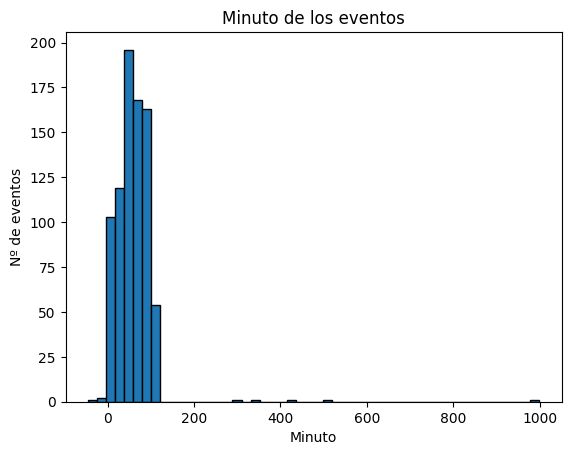

In [15]:
#Minuto de los eventos
eventos["minuto_evento"].plot.hist(bins=50, edgecolor="black", title="Minuto de los eventos")
plt.xlabel("Minuto")
plt.ylabel("Nº de eventos")
plt.show()

Casi todo cae entre 0 y 120, pero hay barras sueltas muy lejos: negativos y hasta 999. Minutos imposibles.

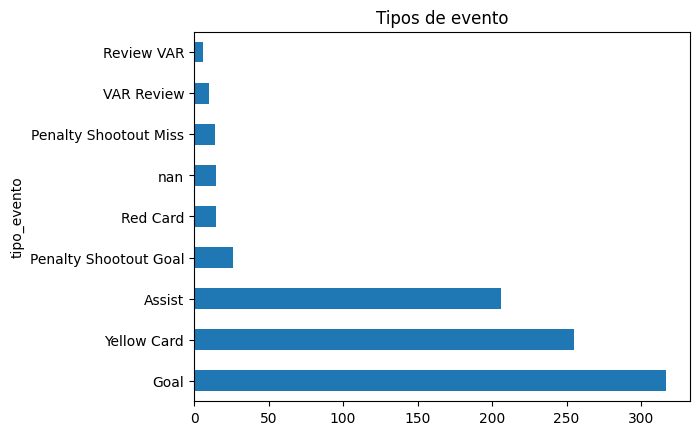

In [16]:
#Tipos de evento
eventos["tipo_evento"].value_counts(dropna=False).plot.barh(title="Tipos de evento")
plt.show()

Salen "VAR Review" y "Review VAR" como si fueran dos tipos distintos, y una barra de NaN (filas vacías). Es una inconsistencia de categorías y hay que unificarlas.

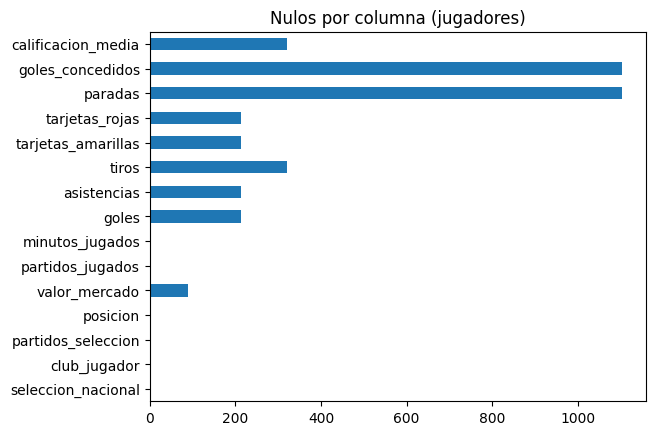

In [17]:
#Nulos por columna en jugadores
jugadores.isna().sum().plot.barh(title="Nulos por columna (jugadores)")
plt.show()

paradas y goles_concedidos tienen muchísimos nulos, porque solo existen para porteros. Por lo que los 1103 nulos son todos los jugadores que no son porteros. Deberíamos de ponerles 0. No es un dato perdido, es un dato que no se escribió. 

goles, asistencias y las tarjetas tienen todas el mismo número (213): son los jugadores que no han jugado. Así se no es que no sepamos cuántos goles metieron: metieron 0. Estos NaN deberián ser 0.

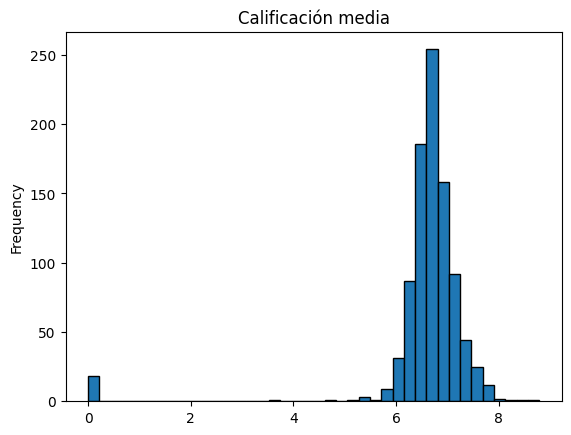

In [18]:
#calificación media
jugadores["calificacion_media"].plot.hist(bins=40, edgecolor="black", title="Calificación media")
plt.show()

Casi todas las notas están entre 6 y 8, pero hay una barrita pegada al 0. Una nota de 0 no es real, así que se pasa a NaN.

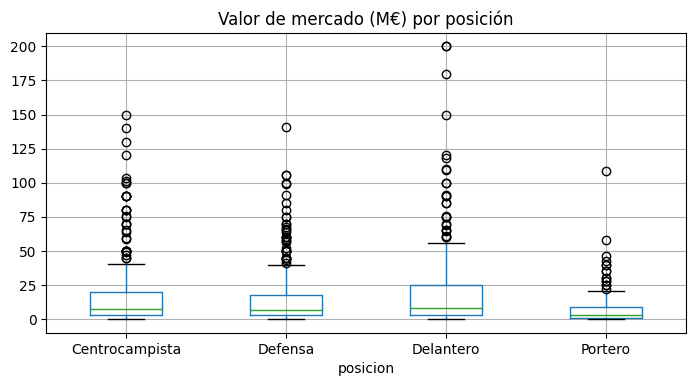

In [19]:
#Valor de mercado de posición
jugadores.boxplot(column="valor_mercado", by="posicion", figsize=(8, 4))
plt.title("Valor de mercado (M€) por posición")
plt.suptitle("")
plt.show()

In [20]:
display(jugadores.sort_values("valor_mercado", ascending=False)[["seleccion_nacional", "club_jugador", "valor_mercado"]].head(10))

,seleccion_nacional,club_jugador,valor_mercado
nombre_jugador,,,
Lamine Yamal Yamal,España,FC Barcelona,200.0000
Erling Braut Haaland,Noruega,Manchester City FC,200.0000
Kylian Mbappe,Francia,Real Madrid C. F.,180.0000
Michael Akpovie Olise,Francia,FC Bayern München,150.0000
Pedro Pedri,España,FC Barcelona,150.0000
Marcos Nicolás Senesi,Argentina,AFC Bournemouth,140.8331
Vitor Vitinha,Portugal,Paris Saint-Germain,140.0000
Jude Victor William Bellingham,Inglaterra,Real Madrid C. F.,130.0000
Declan Rice,Inglaterra,Arsenal FC,120.0000


La "caja" está abajo (la mayoría vale menos de 20 M€) y hay muchos puntos sueltos arriba. Son atípicos, pero son estrellas reales (Yamal, Mbappé...), así que no se borran.

4. Limpieza y tratamiento de datos

In [21]:
#PARTIDOS
display(resumen(partidos))

,dtype,nulos,pct_nulos,n_unicos
fecha_partido,object,0,0.0,96
ronda,object,0,0.0,7
estadio,object,0,0.0,16
ciudad_partido,object,0,0.0,16
pais_partido,object,0,0.0,3
seleccion_local,object,0,0.0,48
seleccion_visitante,object,0,0.0,48
marcador_local,int64,0,0.0,8
marcador_visitante,int64,0,0.0,7
prorroga,object,0,0.0,2


In [22]:
#Duplicados

#son duplicados exactos?
#Como el índice es index_partido, busco índices repetidos
print("Ids repetidos:", partidos.index.duplicated().sum())                 
print("Filas idénticas:", partidos.reset_index().duplicated().sum())   
#coinciden : todos los ids repetidos son copias exactas (no hay versiones distintas del mismo partido)

display(partidos[partidos.index.duplicated(keep=False)].sort_index()[["fecha_partido", "seleccion_local", "seleccion_visitante"]]) #para visualizar las parejas

#Son duplicados exactos (mismo partido y mismos datos), añado al final del archivo y se quita la copia
partidos = partidos[~partidos.index.duplicated(keep="first")].sort_index() #me quedo con las filas que no son copia
print("Partidos:", len(partidos)) #104

Ids repetidos: 6
Filas idénticas: 6


,fecha_partido,seleccion_local,seleccion_visitante
index_partido,,,
10,Jun 14 2026,Países Bajos,Japón
10,Jun 14 2026,Países Bajos,Japón
11,20260614,Costa de Marfil,Ecuador
11,20260614,Costa de Marfil,Ecuador
20,2026-06-16T19:00:00Z,Austria,Jordania
20,2026-06-16T19:00:00Z,Austria,Jordania
33,20.06.2026,Alemania,Costa de Marfil
33,20.06.2026,Alemania,Costa de Marfil
35,20260620,Países Bajos,Suecia


Partidos: 104


In [23]:
#Anómalos: penaltis de la tanda
display(partidos.loc[partidos["penalty_local"].notna(), ["seleccion_local", "seleccion_visitante", "marcador_local",
                                                        "marcador_visitante", "penalty_local", "penalty_visitante"]])

#Regla de dominio: en una tanda cada equipo marca entre 0 y 10 penaltis. 30 o 40 es imposible.
#Todos los valores son múltiplos de 10: sospecho que hubo un error de escala x10.

#Lo compruebo con otra fuente antes de dividir entre 10: en register está cada penalti de la tanda apuntado como evento.
#Voy a contar los "Penalty Shootout Goal" de register por partido y equipo

goles_tanda = register_raw[register_raw["event_type"] == "Penalty Shootout Goal"].drop_duplicates()
display(goles_tanda.groupby(["match_id", "team_id"]).size())

#Salen 3-4, 2-2, 2-4, 4-3: 3 de 4 coinciden exactamente con matches/10.

partidos["penalty_local"] = partidos["penalty_local"] / 10
partidos["penalty_visitante"] = partidos["penalty_visitante"] / 10

,seleccion_local,seleccion_visitante,marcador_local,marcador_visitante,penalty_local,penalty_visitante
index_partido,,,,,,
75,Alemania,Paraguay,1,1,30.0,40.0
76,Países Bajos,Marruecos,1,1,20.0,30.0
86,Australia,Egipto,1,1,20.0,40.0
96,Suiza,Colombia,0,0,40.0,30.0


match_id  team_id
75.0      14.0       4
          17.0       3
76.0      10.0       2
          21.0       2
86.0      15.0       2
          26.0       4
96.0      8.0        4
          44.0       3
dtype: int64

In [24]:
#Nulos
#penalty_local/penalty_visitante: NaN significa "no hubo tanda" así que lo puedo rellenar con 0.
#arbitro_partido: 1 nulo da a entedner que el dato está perdido de verdad. Hay que dejarlo como NaN.

partidos[["penalty_local", "penalty_visitante"]] = partidos[["penalty_local", "penalty_visitante"]].fillna(0)

#arbitro_partido:
#No se rellena: por moda le pondríamos el árbitro más frecuente, que es inventar un dato (mal uso de la moda).
display(partidos[partidos["arbitro_partido"].isna()])



,fecha_partido,ronda,estadio,ciudad_partido,pais_partido,seleccion_local,seleccion_visitante,marcador_local,marcador_visitante,prorroga,penalty_local,penalty_visitante,arbitro_partido
index_partido,,,,,,,,,,,,,
53,"June 25, 2026",Fase de grupos,New York New Jersey Stadium (MetLife Stadium),East Rutherford,Estados Unidos,Escocia,Brasil,0,3,NO,0.0,0.0,NaN


In [25]:
#Comprobaciones de coherencia (reglas cruzadas)

#creo una máscara
hay_tanda = (partidos["penalty_local"] + partidos["penalty_visitante"]) > 0 
#sumo los penaltis de los dos equipos. Si la suma es mayor que 0, ese partido tuvo tanda.

#hay tanda sin empate?
(hay_tanda & (partidos["marcador_local"] != partidos["marcador_visitante"])).sum()
#solo debería de haber tanda si el partido acabó empatado.
#compruebo si hay algun caso donde marcador local y marcador visitante fueran distintos y aúnasí hubiera tanda.
#el resultado es 0 : está bien

#hay tanda sin prórroga?
#la regla es q antes de ka tanda siempre se juega la prórroga
(hay_tanda & (partidos["prorroga"] == "NO")).sum()
#el resultado es 0: está bien


#algún equipo juega contra sí mismo?
#lo que debe de cumplirse es que loca y visitante sean equipos distintos
(partidos["seleccion_local"] == partidos["seleccion_visitante"]).sum()
#el resultado es 0:es correcto

#tipos
partidos[["penalty_local", "penalty_visitante"]] = partidos[["penalty_local", "penalty_visitante"]].astype(int)
#antes: float(3.0, 0.0) eran decimales porque la columna tenia NaN
#ahora int(3,0). lo hemos hecho ahora porque astype(int) da error si queda algún NaN.

partidos.info()
partidos.tail()


<class 'pandas.core.frame.DataFrame'>
Index: 104 entries, 1 to 104
Data columns (total 13 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   fecha_partido        104 non-null    object
 1   ronda                104 non-null    object
 2   estadio              104 non-null    object
 3   ciudad_partido       104 non-null    object
 4   pais_partido         104 non-null    object
 5   seleccion_local      104 non-null    object
 6   seleccion_visitante  104 non-null    object
 7   marcador_local       104 non-null    int64 
 8   marcador_visitante   104 non-null    int64 
 9   prorroga             104 non-null    object
 10  penalty_local        104 non-null    int32 
 11  penalty_visitante    104 non-null    int32 
 12  arbitro_partido      103 non-null    object
dtypes: int32(2), int64(2), object(9)
memory usage: 10.6+ KB


,fecha_partido,ronda,estadio,ciudad_partido,pais_partido,seleccion_local,seleccion_visitante,marcador_local,marcador_visitante,prorroga,penalty_local,penalty_visitante,arbitro_partido
index_partido,,,,,,,,,,,,,
100,12 July 2026,Cuartos,Kansas City Stadium (Arrowhead Stadium),Kansas City,Estados Unidos,Argentina,Suiza,3,1,SI,0,0,João Pinheiro
101,"July 14, 2026",Semifinal,Dallas Stadium (AT&T Stadium),Arlington,Estados Unidos,Francia,España,0,2,NO,0,0,Iván Barton
102,15-jul-26,Semifinal,Atlanta Stadium (Mercedes-Benz Stadium),Atlanta,Estados Unidos,Inglaterra,Argentina,1,2,NO,0,0,Ismail Elfath
103,18/07/2026,Tercer puesto,Miami Stadium (Hard Rock Stadium),Miami Gardens,Estados Unidos,Francia,Inglaterra,4,6,NO,0,0,Jesús Valenzuela
104,2026-07-19T19:00:00Z,Final,New York New Jersey Stadium (MetLife Stadium),East Rutherford,Estados Unidos,España,Argentina,1,0,SI,0,0,Slavko Vincic


In [26]:
#EVENTOS
display(resumen(eventos))

,dtype,nulos,pct_nulos,n_unicos
minuto_evento,float64,53,6.1,119
index_partido,float64,15,1.7,105
nombre_jugador,object,15,1.7,451
tipo_evento,object,15,1.7,9
seleccion_evento,object,15,1.7,49


In [27]:
#15 filas sin partido, jugador ni tipo: no aportan nada
vacios = eventos["index_partido"].isna() & eventos["tipo_evento"].isna()
display(eventos[vacios])
eventos = eventos[~vacios] #,e quedo con las no vacías

,minuto_evento,index_partido,nombre_jugador,tipo_evento,seleccion_evento
index_evento,,,,,
-5,NaN,NaN,NaN,NaN,NaN
-2,NaN,NaN,NaN,NaN,NaN
-45,NaN,NaN,NaN,NaN,NaN
-1,NaN,NaN,NaN,NaN,NaN
-10,NaN,NaN,NaN,NaN,NaN
301,NaN,NaN,NaN,NaN,NaN
350,NaN,NaN,NaN,NaN,NaN
420,NaN,NaN,NaN,NaN,NaN
500,NaN,NaN,NaN,NaN,NaN


In [28]:
#Duplicados exactos
#Como duplicated() no mira el índice y index_evento es el índice, lo pasamos a columna un momento
eventos = eventos.reset_index()
print("Duplicados exactos:", eventos.duplicated().sum())
eventos = eventos.drop_duplicates()

#Duplicados de negocio: tiene el mismo index_evento, pero contenido distinto
display(eventos[eventos.duplicated(subset="index_evento", keep=False)].sort_values("index_evento"))
#Es el mismo evento (mismo partido, jugador y tipo). Lo que cambia es el minuto.
#No hay fecha de actualización para elegir la versión más reciente.
#Nos quedamos con la primera aparición (la original).
eventos = eventos.drop_duplicates(subset="index_evento", keep="first").set_index("index_evento").sort_index()


Duplicados exactos: 15


,index_evento,minuto_evento,index_partido,nombre_jugador,tipo_evento,seleccion_evento
16,17,80.0,2.0,Inbeom Hwang,Assist,Corea del Sur
848,17,999.0,2.0,Inbeom Hwang,Assist,Corea del Sur
40,41,NaN,4.0,Alexander Michael Freeman,Assist,Estados Unidos
844,41,301.0,4.0,Alexander Michael Freeman,Assist,Estados Unidos
136,138,43.0,18.0,Erling Braut Haaland,Goal,Noruega
846,138,420.0,18.0,Erling Braut Haaland,Goal,Noruega
204,206,75.0,27.0,Naceur Mohamed Manai,Goal,Catar
845,206,350.0,27.0,Naceur Mohamed Manai,Goal,Catar
693,698,90.0,91.0,Erling Braut Haaland,Goal,Noruega
847,698,500.0,91.0,Erling Braut Haaland,Goal,Noruega


In [29]:
#Inconsistencia en las categorías
print(eventos["tipo_evento"].value_counts(dropna=False))
# "VAR Review" y "Review VAR" son el mismo evento asi que hacemos replace.Después se traduce con map


eventos["tipo_evento"] = eventos["tipo_evento"].replace({"Review VAR": "VAR Review"})
eventos["tipo_evento"] = eventos["tipo_evento"].map({
    "Goal": "Gol", "Assist": "Asistencia", "Yellow Card": "Tarjeta amarilla",
    "Red Card": "Tarjeta roja", "Penalty Shootout Goal": "Penalti marcado",
    "Penalty Shootout Miss": "Penalti fallado", "VAR Review": "Revisión VAR"})

print(eventos["tipo_evento"].value_counts(dropna=False))


tipo_evento
Goal                     307
Yellow Card              253
Assist                   201
Penalty Shootout Goal     24
Red Card                  15
Penalty Shootout Miss     14
VAR Review                 9
Review VAR                 6
Name: count, dtype: int64
tipo_evento
Gol                 307
Tarjeta amarilla    253
Asistencia          201
Penalti marcado      24
Tarjeta roja         15
Revisión VAR         15
Penalti fallado      14
Name: count, dtype: int64


In [30]:
#Minutos
#Los minutos anómalos
print("Minutos nulos:", eventos["minuto_evento"].isna().sum()) #nulos
print("Minutos fuera de 0-121:", (~eventos["minuto_evento"].between(0, 121) & eventos["minuto_evento"].notna()).sum()) #fuera de rango
print(eventos.loc[eventos["minuto_evento"] == 121, "tipo_evento"].value_counts())   #el 121 = tanda de penaltis

#Tipos
eventos["index_partido"] = eventos["index_partido"].astype(int)
#int normal no admite NaN. "Int64" (con I mayúscula) es el entero de pandas que sí admite nulos
#el minuto debería ser entero, pero todavía tiene 38 NaN que no se pueden rellenar aún
eventos["minuto_evento"] = eventos["minuto_evento"].astype("Int64")
eventos.info()

Minutos nulos: 38
Minutos fuera de 0-121: 5
tipo_evento
Penalti marcado    20
Penalti fallado    13
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 829 entries, 1 to 834
Data columns (total 5 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   minuto_evento     791 non-null    Int64 
 1   index_partido     829 non-null    int32 
 2   nombre_jugador    829 non-null    object
 3   tipo_evento       829 non-null    object
 4   seleccion_evento  829 non-null    object
dtypes: Int64(1), int32(1), object(3)
memory usage: 36.4+ KB


In [31]:
#JUGADORES
display(resumen(jugadores))

print("Duplicados exactos:", jugadores.duplicated().sum())  
# el resultado da 0 (cada fila es un player_id distinto)

#Nulos: son datos desconocidos o un 0 que no se ha escrito?
#Miro los minutos de los jugadores que no tienen goles
display(jugadores.loc[jugadores["goles"].isna(), ["partidos_jugados", "minutos_jugados"]].describe())

#Resultado: Todos tienen 0 minutos así que no han jugado, y sus goles, tarjetas... son 0. No falta el dato, es un 0
no_jugo = jugadores["minutos_jugados"] == 0
cols_contador = ["goles", "asistencias", "tiros", "tarjetas_amarillas", "tarjetas_rojas",
                 "paradas", "goles_concedidos"]
jugadores.loc[no_jugo, cols_contador] = jugadores.loc[no_jugo, cols_contador].fillna(0)


#paradas y goles_concedidos solo se registran para porteros: para el resto, 0
no_portero = jugadores["posicion"] != "Portero"
jugadores.loc[no_portero, ["paradas", "goles_concedidos"]] = jugadores.loc[no_portero, ["paradas", "goles_concedidos"]].fillna(0)

display(resumen(jugadores))

,dtype,nulos,pct_nulos,n_unicos
seleccion_nacional,object,0,0.0,48
club_jugador,object,0,0.0,450
partidos_seleccion,int64,0,0.0,5
posicion,object,0,0.0,4
valor_mercado,float64,90,7.2,523
partidos_jugados,int64,0,0.0,9
minutos_jugados,int64,0,0.0,382
goles,float64,213,17.1,11
asistencias,float64,213,17.1,7
tiros,float64,320,25.6,25


Duplicados exactos: 0


,partidos_jugados,minutos_jugados
count,213.0,213.0
mean,0.0,0.0
std,0.0,0.0
min,0.0,0.0
25%,0.0,0.0
50%,0.0,0.0
75%,0.0,0.0
max,0.0,0.0


,dtype,nulos,pct_nulos,n_unicos
seleccion_nacional,object,0,0.0,48
club_jugador,object,0,0.0,450
partidos_seleccion,int64,0,0.0,5
posicion,object,0,0.0,4
valor_mercado,float64,90,7.2,523
partidos_jugados,int64,0,0.0,9
minutos_jugados,int64,0,0.0,382
goles,float64,0,0.0,10
asistencias,float64,0,0.0,6
tiros,float64,107,8.6,25


In [32]:
#Reglas de dominio
#calificacion_media: escala 0-10, pero un 0 no es una nota real
display(jugadores.loc[jugadores["calificacion_media"] == 0, ["minutos_jugados", "calificacion_media"]])
#Son jugadores de 1-2 minutos: no les dio tiempo a que los valoraran. El 0 es un "sin daro" disfrazado. Se pasa a NaN y luego  más adelante se imputa.
jugadores.loc[jugadores["calificacion_media"] == 0, "calificacion_media"] = np.nan

#comporbamos que ya no qued aninguna nota fuera del rango
print("Notas fuera de (0, 10):", (~jugadores["calificacion_media"].between(0.1, 10) & jugadores["calificacion_media"].notna()).sum())

#valor_mercado: un jugador de Mundial que vale 0€ no es creíble -> NaN y se imputa más adelante
display(jugadores.loc[jugadores["valor_mercado"] <= 0, ["club_jugador", "valor_mercado"]])
jugadores.loc[jugadores["valor_mercado"] <= 0, "valor_mercado"] = np.nan

#Coherencia entre columnas
#un jugador no puede jugar más partidos que su selección
print("Juega más partidos que su selección:", (jugadores["partidos_jugados"] > jugadores["partidos_seleccion"]).sum()) 

#tampoco puede jugar más de 120 minutos
print("Más de 120 min por partido:", (jugadores["minutos_jugados"] > jugadores["partidos_jugados"] * 120).sum())  



,minutos_jugados,calificacion_media
nombre_jugador,,
Maximilian Michael Arfsten,1,0.0
Haji Amir Wright,2,0.0
Fabián Cornelio Balbuena,1,0.0
Mathew David Ryan,1,0.0
Shurandy Ruggerio Sambo,1,0.0
Brandley Mack-Olien Kuwas,1,0.0
Håkan Gustaf Nilsson,1,0.0
Marc Pubill,1,0.0
Borja Iglesias,1,0.0


Notas fuera de (0, 10): 0


,club_jugador,valor_mercado
nombre_jugador,,
Álvaro Fidalgo,Real Betis,0.0


Juega más partidos que su selección: 0
Más de 120 min por partido: 0


Q1=2.70  Q3=18.92  IQR=16.22  -> límite superior 43.25 M€
Candidatos IQR: 108


,seleccion_nacional,club_jugador,valor_mercado
nombre_jugador,,,
Erling Braut Haaland,Noruega,Manchester City FC,200.0000
Lamine Yamal Yamal,España,FC Barcelona,200.0000
Kylian Mbappe,Francia,Real Madrid C. F.,180.0000
Pedro Pedri,España,FC Barcelona,150.0000
Michael Akpovie Olise,Francia,FC Bayern München,150.0000
Marcos Nicolás Senesi,Argentina,AFC Bournemouth,140.8331
Vitor Vitinha,Portugal,Paris Saint-Germain,140.0000
Jude Victor William Bellingham,Inglaterra,Real Madrid C. F.,130.0000
Désiré Nonka-Maho Doue,Francia,Paris Saint-Germain,120.0000


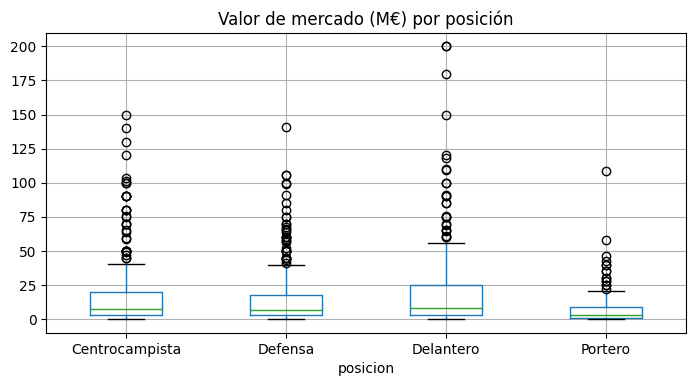

In [33]:
#Atípicos en valor_mercado: criterio IQR

#Cuando hemos hecho el describe() prinicipal al principio, vemos que la media (15,8) es más del doble que la mediana (6.5). 
#Esto quiere decir que unos pocos valores muy altos tiran de la media hacia arriba.
#El máximo (200) es 10 veces el Q3 (18,9), hay un salto enrome entre el 75% de los jugadores y el más caro.

q1 = jugadores["valor_mercado"].quantile(0.25)
q3 = jugadores["valor_mercado"].quantile(0.75)
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr
print(f"Q1={q1:.2f}  Q3={q3:.2f}  IQR={iqr:.2f}  -> límite superior {lim_sup:.2f} M€")

candidatos = jugadores[jugadores["valor_mercado"] > lim_sup]
print("Candidatos IQR:", len(candidatos))
display(candidatos.sort_values("valor_mercado", ascending=False)[["seleccion_nacional", "club_jugador", "valor_mercado"]].head(10))

jugadores.boxplot(column="valor_mercado", by="posicion", figsize=(8, 4))
plt.title("Valor de mercado (M€) por posición")
plt.suptitle("")
plt.show()

#Salen al rededor de 108 candidatos (> 43 M€). See trata de jugadores de grandes clubes, con Yamal, Haaland o Mbappé arriba.
#Un candidato IQR es una alerta, pero no una prueba de error.
#La distribución es asimétrica por naturaleza (pocas estrellas muy caras). 


In [34]:
#Tipos
#Contadores: enteros. "Int64" porque tiros aún tiene NaN
jugadores[cols_contador] = jugadores[cols_contador].astype("Int64") #tiros tenía 107 nulos, los jugadores que jugaron
#pero no tienen tiros apuntados, que decidí dejar como NaN
jugadores.info()

#print(jugadores["tiros"].isna().sum())

<class 'pandas.core.frame.DataFrame'>
Index: 1248 entries, José Raúl Rangel to Jorge Abdiel Gutierrez
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   seleccion_nacional  1248 non-null   object 
 1   club_jugador        1248 non-null   object 
 2   partidos_seleccion  1248 non-null   int64  
 3   posicion            1248 non-null   object 
 4   valor_mercado       1157 non-null   float64
 5   partidos_jugados    1248 non-null   int64  
 6   minutos_jugados     1248 non-null   int64  
 7   goles               1248 non-null   Int64  
 8   asistencias         1248 non-null   Int64  
 9   tiros               1141 non-null   Int64  
 10  tarjetas_amarillas  1248 non-null   Int64  
 11  tarjetas_rojas      1248 non-null   Int64  
 12  paradas             1248 non-null   Int64  
 13  goles_concedidos    1248 non-null   Int64  
 14  calificacion_media  910 non-null    float64
dtypes: Int64(7), float64(2), in

5. Exclusión valores anómalos de eventos

In [35]:
# Recorrer todas las columnas de df_eventos e imprimir la frecuencia de cada valor
for columna in eventos.columns:
    print(f"==================== {columna.upper()} ====================")
    print(eventos[columna].value_counts(dropna=False))
    print("\n")

==================== MINUTO_EVENTO ====================
minuto_evento
90      76
<NA>    38
121     33
45      28
54      16
        ..
-2       1
-1       1
25       1
95       1
-10      1
Name: count, Length: 114, dtype: Int64


==================== INDEX_PARTIDO ====================
index_partido
75     21
103    16
92     16
4      15
96     15
       ..
13      2
47      2
56      2
89      1
69      1
Name: count, Length: 104, dtype: int64


==================== NOMBRE_JUGADOR ====================
nombre_jugador
Kylian Mbappe                     15
Lionel Andrés Messi               12
Jude Victor William Bellingham     9
Harry Edward Kane                  8
Breel Donald Embolo                7
                                  ..
Inaki Williams                     1
Ante Budimir                       1
Josip Stanisic                     1
Edgar Yoel Barcenas                1
Nicholas Williams                  1
Name: count, Length: 450, dtype: int64


==================== TIPO_E

In [36]:
# Copias temporales auxiliares para cruces sin modificar los DF originales
partidos_aux = partidos.reset_index() if 'index_partido' not in partidos.columns else partidos.copy()
jugadores_aux = jugadores.reset_index() if 'nombre_jugador' not in jugadores.columns else jugadores.copy()

# Copia auxiliar con índice explícito
eventos_temp = eventos.copy()
eventos_temp['_idx_orig'] = eventos.index

# Normalizar espacios en texto
for col in ['nombre_jugador', 'tipo_evento', 'seleccion_evento']:
    if col in eventos_temp.columns and eventos_temp[col].dtype == 'object':
        eventos_temp[col] = eventos_temp[col].astype(str).str.strip()

# Lista de tipos de evento válidos
eventos_validos = [
    'Gol', 
    'Asistencia', 
    'Tarjeta amarilla', 
    'Tarjeta roja', 
    'Revisión VAR',
    'Penalti fallado',
    'Penalti marcado'
]

#Me quedo con los indices de las distintas anomalías 

# A. Prórrogas en Fase de Grupos (>100 min)
partidos_grupos = partidos_aux[partidos_aux['ronda'].str.lower().str.contains('grupo')]['index_partido'] if 'ronda' in partidos_aux.columns else range(1, 73)
idx_prorroga_grupos = eventos_temp[
    (eventos_temp['index_partido'].isin(partidos_grupos)) & 
    (eventos_temp['minuto_evento'] > 100)
]['_idx_orig']

# B. Filas duplicadas exactas
idx_duplicados = eventos[eventos.duplicated()].index

# C. Más de 2 tarjetas amarillas al mismo jugador en el mismo partido
amarillas_por_jugador = eventos_temp[eventos_temp['tipo_evento'] == 'Tarjeta amarilla'].groupby(
    ['index_partido', 'nombre_jugador']
).size()
jugadores_exceso_amarillas = amarillas_por_jugador[amarillas_por_jugador > 2].reset_index()[['index_partido', 'nombre_jugador']]
idx_exceso_amarillas = eventos_temp.merge(
    jugadores_exceso_amarillas, 
    on=['index_partido', 'nombre_jugador']
)['_idx_orig']

# D. Asistencias sin gol asociado (Teniendo en cuenta los goles con minuto <NA>)
asistencias = eventos_temp[eventos_temp['tipo_evento'] == 'Asistencia']
goles = eventos_temp[eventos_temp['tipo_evento'].isin(['Gol', 'Penalti marcado'])]

asistencias_con_gol = asistencias.merge(
    goles[['index_partido', 'seleccion_evento', 'minuto_evento']], 
    on=['index_partido', 'seleccion_evento'], 
    how='left', 
    suffixes=('_asistencia', '_gol')
)

es_coincidencia_valida = (
    (asistencias_con_gol['minuto_evento_asistencia'] == asistencias_con_gol['minuto_evento_gol']) | 
    (asistencias_con_gol['minuto_evento_asistencia'].isna()) | 
    (asistencias_con_gol['minuto_evento_gol'].isna())
)

idx_asistencias_validas = asistencias_con_gol[es_coincidencia_valida]['_idx_orig'].unique()
idx_asistencias_sin_gol = asistencias[~asistencias['_idx_orig'].isin(idx_asistencias_validas)]['_idx_orig']

# E. Eventos registrados tras la expulsión del jugador (Tarjeta roja)
rojas = eventos_temp[eventos_temp['tipo_evento'] == 'Tarjeta roja'][['index_partido', 'nombre_jugador', 'minuto_evento']].rename(
    columns={'minuto_evento': 'minuto_expulsion'}
)
eventos_post_roja = eventos_temp.merge(rojas, on=['index_partido', 'nombre_jugador'])
idx_eventos_post_roja = eventos_post_roja[
    eventos_post_roja['minuto_evento'] > eventos_post_roja['minuto_expulsion']
]['_idx_orig']

# F. Contradicción: Gol y Penalti fallado en el mismo minuto por el mismo jugador
penaltis_fallados = eventos_temp[eventos_temp['tipo_evento'] == 'Penalti fallado']
goles_mismo_minuto = eventos_temp[eventos_temp['tipo_evento'] == 'Gol']
idx_penalti_gol_contradictorio = penaltis_fallados.merge(
    goles_mismo_minuto, 
    on=['index_partido', 'nombre_jugador', 'minuto_evento']
)['_idx_orig_x']

# H. Jugador registrado en una selección que no es la suya oficial
eventos_con_jugador = eventos_temp.merge(
    jugadores_aux[['nombre_jugador', 'seleccion_nacional']], 
    on='nombre_jugador', 
    how='left'
)
idx_jugador_seleccion_incorrecta = eventos_con_jugador[
    (eventos_con_jugador['seleccion_nacional'].notna()) & 
    (eventos_con_jugador['seleccion_evento'] != eventos_con_jugador['seleccion_nacional'])
]['_idx_orig']

# I. Selección del evento que no participa en el partido
eventos_con_partido = eventos_temp.merge(
    partidos_aux[['index_partido', 'seleccion_local', 'seleccion_visitante']], 
    on='index_partido', 
    how='left'
)
idx_seleccion_fuera_de_partido = eventos_con_partido[
    (eventos_con_partido['seleccion_evento'] != eventos_con_partido['seleccion_local']) & 
    (eventos_con_partido['seleccion_evento'] != eventos_con_partido['seleccion_visitante'])
]['_idx_orig']


# Minuto fuera de rango (menor que 0 o mayor que 121; preserva <NA>)
cond_minuto = (
    ((eventos['minuto_evento'] >= 0) & (eventos['minuto_evento'] <= 121)) | 
    (eventos['minuto_evento'].isna())
)

cond_partido = (eventos['index_partido'] >= 1) & (eventos['index_partido'] <= 104)
cond_tipo = eventos['tipo_evento'].isin(eventos_validos)
cond_seleccion = (
    eventos['seleccion_evento'].notna() & 
    (eventos['seleccion_evento'].astype(str).str.strip() != '')
)

#me creo el diccionario de razones de anomalía para añadirlo posteriormente al dataframe y poder ver la causa de la anomalía

razones = {idx: [] for idx in eventos.index}

for idx in eventos[~cond_minuto].index:
    razones[idx].append("Minuto fuera de rango (<0 o >121)")
for idx in eventos[~cond_partido].index:
    razones[idx].append("Índice de partido fuera de rango (<1 o >104)")
for idx in eventos[~cond_tipo].index:
    razones[idx].append("Tipo de evento no válido")
for idx in eventos[~cond_seleccion].index:
    razones[idx].append("Selección del evento nula o vacía")
for idx in idx_prorroga_grupos:
    razones[idx].append("Prórroga en fase de grupos")
for idx in idx_duplicados:
    razones[idx].append("Fila duplicada")
for idx in idx_exceso_amarillas:
    razones[idx].append("Jugador con >2 amarillas en el mismo partido")
for idx in idx_asistencias_sin_gol:
    razones[idx].append("Asistencia sin gol asociado")
for idx in idx_eventos_post_roja:
    razones[idx].append("Evento registrado tras expulsión del jugador")
for idx in idx_penalti_gol_contradictorio:
    razones[idx].append("Contradicción: Gol y Penalti fallado en mismo minuto")
for idx in idx_jugador_seleccion_incorrecta:
    razones[idx].append("Jugador en selección distinta a su nacional")
for idx in idx_seleccion_fuera_de_partido:
    razones[idx].append("Selección del evento no participa en el partido")

serie_razones = pd.Series(
    {idx: " | ".join(motivos) for idx, motivos in razones.items() if motivos}
)

mascara_validos = ~eventos.index.isin(serie_razones.index)

df_anomalos = eventos[~mascara_validos].copy()
df_anomalos['razon_anomalia'] = df_anomalos.index.map(serie_razones)

eventos_limpios = eventos[mascara_validos].copy()

#Hago el reporte y la verificación

print("=== REPORTE DE CONDICIONES Y ANOMALÍAS DETECTADAS ===")
print("--- Condiciones de formato y rango ---")
print(f"Minutos fuera de rango (<0 o >121): {(~cond_minuto).sum()}")
print(f"Índices de partido fuera de rango (<1 o >104): {(~cond_partido).sum()}")
print(f"Tipos de evento no válidos: {(~cond_tipo).sum()}")
print(f"Selecciones del evento nulas o vacías: {(~cond_seleccion).sum()}")

print("\n--- Anomalías lógicas ---")
print(f"Prórrogas en fase de grupos: {len(idx_prorroga_grupos)}")
print(f"Filas duplicadas: {len(idx_duplicados)}")
print(f"Jugadores con >2 amarillas: {len(idx_exceso_amarillas)}")
print(f"Asistencias sin gol asociado: {len(idx_asistencias_sin_gol)}")
print(f"Eventos tras expulsión: {len(idx_eventos_post_roja)}")
print(f"Contradicciones Gol y Penalti fallado: {len(idx_penalti_gol_contradictorio)}")
print(f"Jugador registrado en selección incorrecta (H): {len(idx_jugador_seleccion_incorrecta)}")
print(f"Selección del evento que no juega ese partido (I): {len(idx_seleccion_fuera_de_partido)}")

print("\n=== RESUMEN GLOBAL DE FILTRADO ===")
print(f"Total registros originales: {len(eventos)}")
print(f"Registros anómalos borrados: {len(df_anomalos)}")
print(f"Registros limpios restantes: {len(eventos_limpios)}")
display(df_anomalos)

=== REPORTE DE CONDICIONES Y ANOMALÍAS DETECTADAS ===
--- Condiciones de formato y rango ---
Minutos fuera de rango (<0 o >121): 5
Índices de partido fuera de rango (<1 o >104): 0
Tipos de evento no válidos: 0
Selecciones del evento nulas o vacías: 0

--- Anomalías lógicas ---
Prórrogas en fase de grupos: 0
Filas duplicadas: 1
Jugadores con >2 amarillas: 0
Asistencias sin gol asociado: 2
Eventos tras expulsión: 0
Contradicciones Gol y Penalti fallado: 0
Jugador registrado en selección incorrecta (H): 0
Selección del evento que no juega ese partido (I): 0

=== RESUMEN GLOBAL DE FILTRADO ===
Total registros originales: 829
Registros anómalos borrados: 7
Registros limpios restantes: 822


,minuto_evento,index_partido,nombre_jugador,tipo_evento,seleccion_evento,razon_anomalia
index_evento,,,,,,
109,-5,14,Timothy Castagne,Tarjeta amarilla,Bélgica,Minuto fuera de rango (<0 o >121)
123,-2,16,Mohammad Mohebbi,Gol,Irán,Minuto fuera de rango (<0 o >121)
124,64,16,Ramin Rezaeian,Asistencia,Irán,Asistencia sin gol asociado
161,-10,21,SEMEDONélson Nelson,Tarjeta amarilla,Portugal,Minuto fuera de rango (<0 o >121)
267,-45,35,Denzel Justus Morris Dumfries,Asistencia,Países Bajos,Minuto fuera de rango (<0 o >121) | Asistencia...
524,<NA>,68,Riyad Karim Mahrez,Gol,Argelia,Fila duplicada
532,-1,70,Abdukodir Khusanov,Tarjeta amarilla,Uzbekistán,Minuto fuera de rango (<0 o >121)


6. Reconstrucción "fecha_partido"

In [37]:
import re

# Diccionario unificado para mapear meses (solo junio y julio, meses del mundial) en español e inglés
MESES = {
    'jun': 6, 'june': 6, 'junio': 6,
    'jul': 7, 'july': 7, 'julio': 7,
}

# Mapeo para obtener el nombre completo del mes (mmmm)
NOMBRES_MESES = {
    1: 'enero', 2: 'febrero', 3: 'marzo', 4: 'abril',
    5: 'mayo', 6: 'junio', 7: 'julio', 8: 'agosto',
    9: 'septiembre', 10: 'octubre', 11: 'noviembre', 12: 'diciembre'
}

def normalizar_anio_2d(anio_str):
    """Devuelve el año en formato 2 dígitos (aa)."""
    if not anio_str or len(anio_str) < 2:
        return "26"
    return str(anio_str)[-2:]

def formatear_salida(dia, mes_num, anio_str):
    """Auxiliar para construir la fecha en formato dd/mmmm/aa."""
    dd = f"{int(dia):02d}"
    mmmm = NOMBRES_MESES.get(int(mes_num), 'junio')
    aa = normalizar_anio_2d(anio_str)
    return f"{dd}/{mmmm}/{aa}"

def parsear_fecha_regex(val):
    if pd.isna(val):
        return None
    
    val_str = str(val).strip()
    
    # 1. ISO 8601 con tiempo: 2026-06-19T19:00:00Z
    m = re.match(r'^(\d{4})-(\d{2})-(\d{2})T', val_str)
    if m:
        return formatear_salida(m.group(3), m.group(2), m.group(1))
    
    # 2. Compacto numérico sin separadores: 20260614
    m = re.match(r'^(\d{4})(\d{2})(\d{2})$', val_str)
    if m:
        return formatear_salida(m.group(3), m.group(2), m.group(1))
    
    # 3. Español formal: 14 de junio de 2026
    m = re.match(r'^(\d{1,2})\s+de\s+([a-zA-Z]+)(?:\s+de\s+(\d{2,4}))?$', val_str, re.IGNORECASE)
    if m:
        dia, mes_str, anio = m.groups()
        mes = MESES.get(mes_str.lower(), 6)
        return formatear_salida(dia, mes, anio)
    
    # 4. Texto inglés (Mes Día Año): June 13, 2026  o  June 14 2026
    m = re.match(r'^([a-zA-Z]+)\s+(\d{1,2}),?\s*(\d{2,4})?$', val_str)
    if m:
        mes_str, dia, anio = m.groups()
        mes = MESES.get(mes_str.lower(), 6)
        return formatear_salida(dia, mes, anio)
    
    # 5. Día + Texto Mes + Año: 15 June 2026 / 15 June 202 / 13-jun-26
    m = re.match(r'^(\d{1,2})[-/ ]([a-zA-Z]+)(?:[-/ ](\d{2,4}))?$', val_str)
    if m:
        dia, mes_str, anio = m.groups()
        mes = MESES.get(mes_str.lower()[:3], 6)
        return formatear_salida(dia, mes, anio)
    
    # 6. Formato Numérico con Puntos: 14.06.2026
    m = re.match(r'^(\d{1,2})\.(\d{1,2})\.(\d{2,4})$', val_str)
    if m:
        dia, mes, anio = m.groups()
        return formatear_salida(dia, mes, anio)
    
    # 7. Formato Americano con Guiones MM-DD-YYYY: 06-15-2026
    m = re.match(r'^(\d{2})-(\d{2})-(\d{2,4})$', val_str)
    if m:
        mes, dia, anio = m.groups()
        return formatear_salida(dia, mes, anio)
    
    # 8. Formato Estándar DD/MM/YYYY: 13/06/2026
    m = re.match(r'^(\d{1,2})/(\d{1,2})/(\d{2,4})$', val_str)
    if m:
        dia, mes, anio = m.groups()
        return formatear_salida(dia, mes, anio)

    return val_str

# Aplicar a la columna de fechas en partidos
col_fecha = [c for c in partidos.columns if 'fecha' in c.lower()][0]
partidos['fecha_partido'] = partidos[col_fecha].apply(parsear_fecha_regex)

7. Imputación 

In [38]:
jugadores['valor_mercado'] = jugadores['valor_mercado'].fillna(
    jugadores.groupby('seleccion_nacional')['valor_mercado'].transform('mean')
)

In [39]:
from sklearn.linear_model import LinearRegression

# Creamos una copia para imputar
jugadores_imputed = jugadores.copy()

# Definimos las variables explicativas (X) según la posición
features_campo = ['goles', 'asistencias', 'tarjetas_amarillas', 'tarjetas_rojas']
features_porteros = ['paradas', 'goles_concedidos', 'tarjetas_amarillas', 'tarjetas_rojas']

# Máscara para identificar porteros frente a jugadores de campo
mask_portero = jugadores_imputed['posicion'].str.contains('Portero', na=False)

# Entrenamos con los jugadores de campo que sí tienen calificación completa
train_campo = jugadores_imputed[~mask_portero].dropna(subset=['calificacion_media'])

# Entrenamos el modelo. El modelo aprende la relación entre las variables explicativas y calificacion_media.
# .fit(X, y) x- variable explicativa, goles, asistencias...; y - variable objetivo - calificacion_media
model_campo = LinearRegression().fit(
    train_campo[features_campo],
    train_campo['calificacion_media']
)

# Máscara de nulos para jugadores de campo
mask_null_campo = ~mask_portero & jugadores_imputed['calificacion_media'].isna()

# Filtramos los valores faltantes y predecimos sus valores a partir del modelo
jugadores_imputed.loc[mask_null_campo, 'calificacion_media'] = model_campo.predict(
    jugadores_imputed.loc[mask_null_campo, features_campo]
)


# Entrenamos con los porteros que sí tienen calificación completa
train_porteros = jugadores_imputed[mask_portero].dropna(subset=['calificacion_media'])

# Entrenamos el modelo. El modelo aprende la relación entre las variables explicativas y calificacion_media.
# .fit(X, y) x- variable explicativa, goles_concedidos, paradas...; y - variable objetivo - calificacion_media
model_porteros = LinearRegression().fit(
    train_porteros[features_porteros],
    train_porteros['calificacion_media']
)

# Máscara de nulos para porteros
mask_null_portero = mask_portero & jugadores_imputed['calificacion_media'].isna()

# Filtramos los valores faltantes y predecimos sus valores a partir del modelo
jugadores_imputed.loc[mask_null_portero, 'calificacion_media'] = model_porteros.predict(
    jugadores_imputed.loc[mask_null_portero, features_porteros]
)

# Marcamos los datos que fueron imputados
jugadores_imputed['imputed_calificacion'] = jugadores['calificacion_media'].isna()

# Acotación al rango [0, 10] y redondeo
jugadores_imputed['calificacion_media'] = jugadores_imputed['calificacion_media'].clip(0, 10).round(2)

# Ver el conteo de nulos por columna
print("Nulos en calificacion_media antes:", jugadores['calificacion_media'].isna().sum())
print("Nulos en calificacion_media después:", jugadores_imputed['calificacion_media'].isna().sum())

Nulos en calificacion_media antes: 338
Nulos en calificacion_media después: 0


In [40]:
# Crear una copia para imputar
eventos_interpolated = eventos_limpios.copy()

# Imputación por interpolación lineal agrupando por partido
eventos_interpolated["minuto_evento"] = (
    eventos_interpolated
    .groupby("index_partido")["minuto_evento"]
    .transform(lambda group: group.interpolate("linear"))  # La interpolación lineal calcula los valores faltantes siguiendo una línea recta entre los eventos previos y posteriores del mismo partido.
)

# En caso de que el primer o último evento de un partido tenga un valor faltante, se realiza un rellenado hacia adelante/atrás dentro del propio partido
eventos_interpolated["minuto_evento"] = (
    eventos_interpolated
    .groupby("index_partido")["minuto_evento"]
    .transform(lambda group: group.ffill().bfill())
)

# Redondear al entero más cercano (los minutos de evento son valores discretos)
eventos_interpolated["minuto_evento"] = eventos_interpolated["minuto_evento"].round().astype("Int64")

# Verificación de resultados
print("Nulos en minuto_evento antes:", eventos_limpios["minuto_evento"].isna().sum())
print("Nulos en minuto_evento después:", eventos_interpolated["minuto_evento"].isna().sum())

Nulos en minuto_evento antes: 37
Nulos en minuto_evento después: 0


8. Exportación final

In [41]:
# Exportar el DataFrame de Partidos
partidos.to_excel('partidosWC26.xlsx', index=False)

# Exportar el DataFrame de Eventos (utilizando la versión limpia e imputada)
eventos_interpolated.to_excel('eventosWC26.xlsx', index=False)

# Exportar el DataFrame de Jugadores (utilizando la versión imputada)
jugadores_imputed.to_excel('jugadoresWC2026.xlsx', index=True)

print("¡Exportación completada con éxito!")

¡Exportación completada con éxito!


In [42]:
jugadores_imputed

,seleccion_nacional,club_jugador,partidos_seleccion,posicion,valor_mercado,partidos_jugados,minutos_jugados,goles,asistencias,tiros,tarjetas_amarillas,tarjetas_rojas,paradas,goles_concedidos,calificacion_media,imputed_calificacion
nombre_jugador,,,,,,,,,,,,,,,,
José Raúl Rangel,México,CD Guadalajara,5,Portero,8.933600,5,438,0,0,0,0,0,7,3,7.20,False
Jorge Eduardo Sanchez,México,PAOK Saloniki,5,Defensa,24.628600,4,349,0,1,1,1,0,0,0,6.68,False
César Jasib Montes,México,FC Lokomotiv Moscow,5,Defensa,10.912600,4,315,0,0,1,0,1,0,0,7.05,False
Edson Omar Alvarez,México,Fenerbahçe SK,5,Defensa,10.875900,4,239,0,0,2,1,0,0,0,7.08,False
Johan Felipe Vasquez,México,Genoa CFC,5,Defensa,18.265400,4,360,0,0,1,1,0,0,0,7.08,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Orlando Mosquera,Panamá,Al Fayha FC,3,Portero,0.700000,3,270,0,0,0,0,0,8,4,6.80,False
Michael Amir Murillo,Panamá,Be ş ikta ş JK,3,Defensa,7.830200,3,270,0,0,5,0,0,0,0,6.93,False
Azarías Emmanuel Londono,Panamá,CD Universidad Católica,3,Delantero,4.490400,3,53,0,0,1,0,0,0,0,6.57,False
